# Ejercicio 1. Verificación numérica

Este cuaderno acompaña al informe [`ejercicio-01.md`](ejercicio-01.md). Calcula todos los valores citados en él, comprueba las proposiciones con casos de prueba y genera la Figura 1 (`ejercicio-01.png`). Las secciones siguen la numeración del informe.

Se usa el modelo de la conferencia 1, sección 7: $10^9$ operaciones por segundo y un presupuesto de una hora, $B = 3{,}6 \cdot 10^{12}$ operaciones.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import lambertw

OPS_PER_SECOND = 10**9
HOUR = 3600 * OPS_PER_SECOND
K = 1000  # cuántas veces más rápida es la computadora nueva

BUDGETS = [
    ("1 s", 1),
    ("1 min", 60),
    ("1 h", 3600),
    ("1 día", 86_400),
    ("1 año", 365 * 86_400),
    ("1 siglo", 100 * 365 * 86_400),
]

## 1. Formulación

$N(B) = \max\{n : T(n) \le B\}$ se calcula por búsqueda binaria con la función `largest_n` de la conferencia 1, sección 7, con los identificadores en inglés. El factor estudiado es $f(B) = N(1000B)/N(B)$.

In [2]:
def largest_n(cost, budget):
    # el mayor n con costo(n) <= presupuesto, por búsqueda binaria
    high = 2
    while cost(high) <= budget:
        high *= 2
    low = high // 2
    while low + 1 < high:
        mid = (low + high) // 2
        if cost(mid) <= budget:
            low = mid
        else:
            high = mid
    return low


def quadratic(n):
    return n * n


def n_log_n(n):
    return n * math.log2(n)


def factor(cost, budget, k=K):
    return largest_n(cost, k * budget) / largest_n(cost, budget)

## 2. Costo cuadrático

Valores de la Proposición 1 con $c = 1$ y una hora, y el factor $1000^{1/a}$ para $T(n) = n^a$.

In [3]:
N = largest_n(quadratic, HOUR)
new_N = largest_n(quadratic, K * HOUR)
print(f"N(B) = {N:,}   N(1000B) = {new_N:,}   f = {new_N / N:.2f}")
print(f"sqrt(1000) = {math.sqrt(K):.4f}   cota del redondeo sqrt(1000)/N = {math.sqrt(K) / N:.1e}")
print()
for a in [1, 2, 3]:
    print(f"n^{a}: f = {factor(lambda n, a=a: n**a, HOUR):8.2f}   1000^(1/{a}) = {K ** (1 / a):8.2f}")

N(B) = 1,897,366   N(1000B) = 60,000,000   f = 31.62
sqrt(1000) = 31.6228   cota del redondeo sqrt(1000)/N = 1.7e-05

n^1: f =  1000.00   1000^(1/1) =  1000.00
n^2: f =    31.62   1000^(1/2) =    31.62
n^3: f =    10.00   1000^(1/3) =    10.00


Tabla 1: convergencia de la Proposición 2 para dos costos en $\Theta(n^2)$. El primero es el polinomio del ejercicio 1 de la conferencia 1.

In [4]:
theta_costs = [
    ("3n^2 + 10 n log n + 7", lambda n: 3 * n * n + 10 * n * math.log2(n) + 7),
    ("n^2 + 10^6 n", lambda n: n * n + 10**6 * n),
]
print(f"{'costo':>22} " + " ".join(f"{name:>8}" for name, _ in BUDGETS))
for name, cost in theta_costs:
    row = [factor(cost, s * OPS_PER_SECOND) for _, s in BUDGETS]
    print(f"{name:>22} " + " ".join(f"{x:>8.2f}" for x in row))

                 costo      1 s    1 min      1 h    1 día    1 año  1 siglo
 3n^2 + 10 n log n + 7    31.66    31.63    31.62    31.62    31.62    31.62
          n^2 + 10^6 n   618.65   127.91    40.70    33.31    31.71    31.63


## 3. Costo $n \log n$

Cotas de la Proposición 4 e iteración de $\varphi(t) = 1000L/(L + \log t)$ a partir de 1000, con $L = \log_2 N(B)$.

In [5]:
def iterate_phi(L, k=K, steps=50):
    f = k
    history = [f]
    for _ in range(steps):
        f = k * L / (L + math.log2(f))
        history.append(f)
    return history


N = largest_n(n_log_n, HOUR)
new_N = largest_n(n_log_n, K * HOUR)
L = math.log2(N)
history = iterate_phi(L)
print(f"N(B) = {N:,}   N(1000B) = {new_N:,}   f = {new_N / N:.2f}")
print(f"L = log2 N = {L:.2f}")
print("iteración: " + "; ".join(f"{x:.1f}" for x in history[:5]) + "; ...")
print(f"punto fijo: {history[-1]:.2f}")

N(B) = 98,574,774,544   N(1000B) = 78,008,697,597,778   f = 791.37
L = log2 N = 36.52
iteración: 1000.0; 785.6; 791.5; 791.4; 791.4; ...
punto fijo: 791.37


Cálculo de $L$ sin computadora: de $x \log x = B$ se tiene $L = \log B - \log L$, y se itera a partir de $\log B$.

In [6]:
def iterate_L(B, steps=3):
    L = math.log2(B)
    history = [L]
    for _ in range(steps):
        L = math.log2(B) - math.log2(L)
        history.append(L)
    return history


print("L: " + "; ".join(f"{x:.2f}" for x in iterate_L(HOUR)))
print(f"log2 N(B) de la búsqueda: {math.log2(N):.2f}")

L: 41.71; 36.33; 36.53; 36.52
log2 N(B) de la búsqueda: 36.52


Forma cerrada con la función $W$ de Lambert: $n \log_2 n = B$ equivale a $n = z/W(z)$ con $z = B \ln 2$, y $f = 1000\, W(z)/W(1000z)$.

In [7]:
def inverse_n_log_n(budget):
    z = budget * math.log(2)
    return z / lambertw(z).real


def closed_form_n_log_n_factor(budget, k=K):
    return inverse_n_log_n(k * budget) / inverse_n_log_n(budget)


print(f"f con la W de Lambert: {closed_form_n_log_n_factor(HOUR):.2f}")

f con la W de Lambert: 791.37


Tabla 2: dependencia de $f$ respecto del presupuesto (con $c = 1$) y de la constante (con una hora).

In [8]:
print(f"{'presupuesto':>11} " + " ".join(f"{name:>8}" for name, _ in BUDGETS))
for name, cost in [("n log n", n_log_n), ("n^2", quadratic)]:
    row = [factor(cost, s * OPS_PER_SECOND) for _, s in BUDGETS]
    print(f"{name:>11} " + " ".join(f"{x:>8.2f}" for x in row))
print()
constants = [1, 10, 100, 1000]
print(f"{'c':>11} " + " ".join(f"{c:>8}" for c in constants))
for name, cost in [("c n log n", n_log_n), ("c n^2", quadratic)]:
    row = [factor(lambda n, c=c: c * cost(n), HOUR) for c in constants]
    print(f"{name:>11} " + " ".join(f"{x:>8.2f}" for x in row))

presupuesto      1 s    1 min      1 h    1 día    1 año  1 siglo
    n log n   726.44   763.16   791.37   809.09   835.19   851.14
        n^2    31.62    31.62    31.62    31.62    31.62    31.62

          c        1       10      100     1000
  c n log n   791.37   776.37   759.12   739.06
      c n^2    31.62    31.62    31.62    31.62


Convergencia a 1000 según la Proposición 5: despejando $L$ en $1000 - f = f \log f / L$ se obtiene el tamaño necesario para un factor dado. Al final, los valores usados en la interpretación de la sección 3.

In [9]:
for target in [900, 990]:
    target_L = target * math.log2(target) / (K - target)
    print(f"f = {target}: hace falta log2 N = {target_L:.1f}, es decir N ~ 2^{target_L:.0f}")

new_L = math.log2(new_N)
print()
print(f"log2 N(B) = {L:.2f}   log2 N(1000B) = {new_L:.2f}")
print(f"aumento del costo por elemento: {new_L / L:.4f}")
print(f"f por ese aumento: {new_N / N * new_L / L:.1f}")

f = 900: hace falta log2 N = 88.3, es decir N ~ 2^88
f = 990: hace falta log2 N = 985.2, es decir N ~ 2^985

log2 N(B) = 36.52   log2 N(1000B) = 46.15
aumento del costo por elemento: 1.2636
f por ese aumento: 1000.0


## 4. Validez del modelo

Memoria de la entrada de tamaño $N(1000B)$ con 8 bytes por elemento, y bits que necesitan los índices ($\log_2 N(1000B)$) y el contador de operaciones ($\log_2 1000B$), para cada presupuesto.

In [10]:
BYTES_PER_ELEMENT = 8


def format_bytes(b):
    for unit in ["B", "KB", "MB", "GB", "TB", "PB", "EB", "ZB"]:
        if b < 1000:
            return f"{b:.3g} {unit}"
        b /= 1000
    return f"{b:.3g} YB"


print(f"{'presupuesto':>11} {'memoria n^2':>12} {'memoria n log n':>16} "
      f"{'bits índice':>12} {'bits contador':>14}")
for name, s in BUDGETS:
    B = K * s * OPS_PER_SECOND
    N_quadratic, N_nlogn = largest_n(quadratic, B), largest_n(n_log_n, B)
    print(f"{name:>11} {format_bytes(N_quadratic * BYTES_PER_ELEMENT):>12} "
          f"{format_bytes(N_nlogn * BYTES_PER_ELEMENT):>16} "
          f"{math.log2(N_nlogn):>12.2f} {math.log2(B):>14.2f}")

presupuesto  memoria n^2  memoria n log n  bits índice  bits contador
        1 s         8 MB           230 GB        34.74          39.86
      1 min        62 MB          11.9 TB        40.43          45.77
        1 h       480 MB           624 TB        46.15          51.68
      1 día      2.35 GB          13.7 PB        50.60          56.26
      1 año      44.9 GB          4.28 EB        58.89          64.77
    1 siglo       449 GB           386 EB        65.39          71.42


## 5. Casos de prueba

Cada celda termina con `ok` si todas sus aserciones se cumplen.

In [11]:
# Proposición 1: N(B) es la raíz entera y |f - sqrt(1000)| < sqrt(1000)/N,
# para seis presupuestos y tres constantes.
for _, s in BUDGETS:
    B = s * OPS_PER_SECOND
    assert largest_n(quadratic, B) == math.isqrt(B)
    for c in [1, 7, 1000]:
        N1 = largest_n(lambda n: c * n * n, B)
        N2 = largest_n(lambda n: c * n * n, K * B)
        assert abs(N2 / N1 - math.sqrt(K)) < math.sqrt(K) / N1
print("ok")

ok


In [12]:
# Sección 3: búsqueda directa, iteración de phi y forma cerrada coinciden.
for _, s in BUDGETS:
    B = s * OPS_PER_SECOND
    direct = factor(n_log_n, B)
    closed_form = closed_form_n_log_n_factor(B)
    iterated = iterate_phi(math.log2(largest_n(n_log_n, B)))[-1]
    assert abs(direct - closed_form) < 1e-3 * closed_form, (direct, closed_form)
    assert abs(direct - iterated) < 1e-3 * iterated, (direct, iterated)
print("ok")

ok


In [13]:
# Proposiciones 4 y 5: cotas, y monotonía en el presupuesto.
previous = 0
for _, s in BUDGETS:
    B = s * OPS_PER_SECOND
    L0 = math.log2(largest_n(n_log_n, B))
    f0 = factor(n_log_n, B)
    assert K * L0 / (L0 + math.log2(K)) - 1 < f0 < K
    assert f0 > previous
    previous = f0
print("ok")

ok


In [14]:
# Costo n^a: el factor es 1000^(1/a).
for a in [1, 2, 3]:
    f_a = factor(lambda n, a=a: n**a, HOUR)
    assert abs(f_a - K ** (1 / a)) < 0.01 * K ** (1 / a), (a, f_a)
print("ok")

ok


In [15]:
# Lema 3: dado el tamaño x, la solución de (1) no depende de la base del logaritmo.
def solve_equation_1(x, log, steps=60):
    L = log(x)
    f = K
    for _ in range(steps):
        f = K * L / (L + log(f))
    return f


for _, s in BUDGETS:
    x = largest_n(n_log_n, s * OPS_PER_SECOND)
    f2 = solve_equation_1(x, math.log2)
    assert abs(solve_equation_1(x, math.log) - f2) < 1e-9 * f2
    assert abs(solve_equation_1(x, math.log10) - f2) < 1e-9 * f2
print("ok")

ok


In [16]:
# Cálculo de L a mano: tres pasos bastan para error menor que 0,01.
for _, s in BUDGETS:
    B = s * OPS_PER_SECOND
    assert abs(iterate_L(B)[-1] - math.log2(largest_n(n_log_n, B))) < 0.01
print("ok")

ok


In [17]:
# Sección 4: con una hora todo cabe en 64 bits; con un año no cabe el contador;
# con un siglo tampoco caben los índices del algoritmo n log n.
def bits(s):
    B = K * s * OPS_PER_SECOND
    return math.log2(largest_n(n_log_n, B)), math.log2(B)


index_bits, counter_bits = bits(3600)
assert index_bits < 64 and counter_bits < 64
index_bits, counter_bits = bits(365 * 86_400)
assert index_bits < 64 < counter_bits
index_bits, counter_bits = bits(100 * 365 * 86_400)
assert 64 < index_bits < counter_bits
assert 600e12 < largest_n(n_log_n, K * HOUR) * BYTES_PER_ELEMENT < 700e12
assert largest_n(quadratic, K * HOUR) * BYTES_PER_ELEMENT == 480_000_000
print("ok")

ok


## Figura 1

Factor $f(B)$ en función del presupuesto para $n \log n$ y $n^2$. Se guarda también como `ejercicio-01.png`, que es la imagen que incluye el informe.

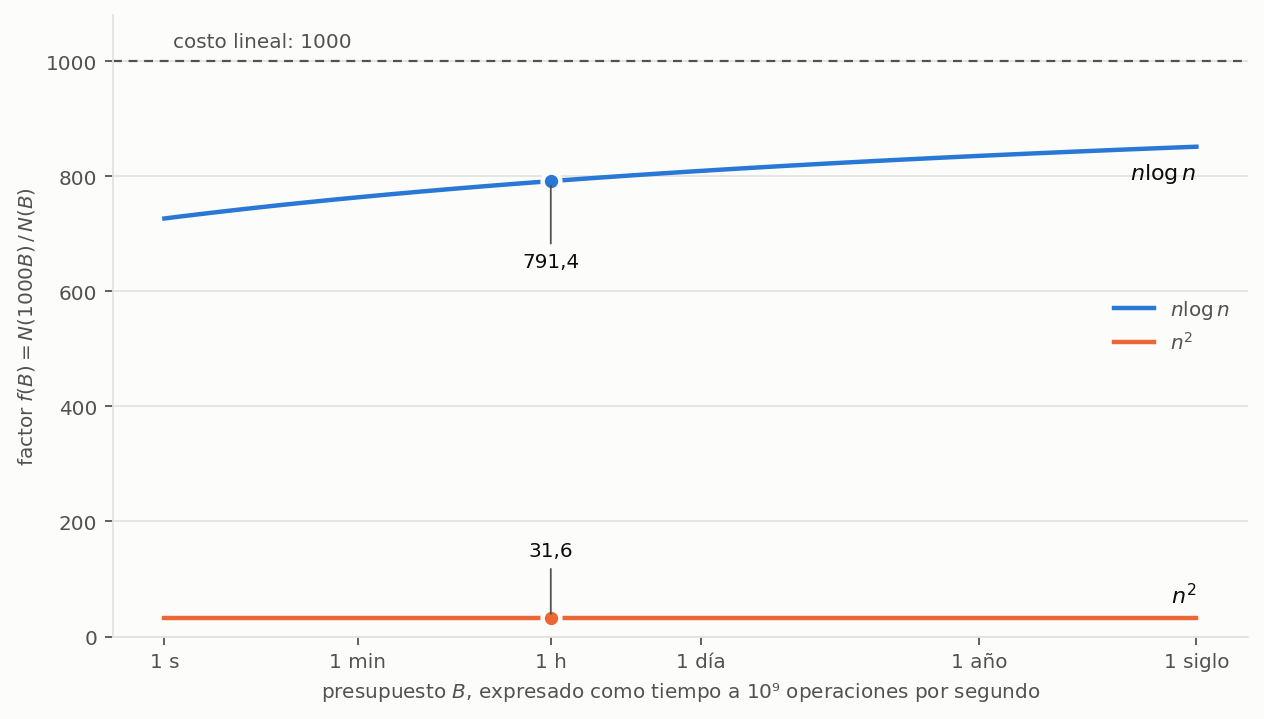

In [18]:
blue, orange = "#2a78d6", "#eb6834"
ink, secondary_ink, grid_color, background = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

seconds = np.logspace(0, math.log10(100 * 365 * 86_400), 60)
curve = [closed_form_n_log_n_factor(s * OPS_PER_SECOND) for s in seconds]
square_root = math.sqrt(K)
hourly_factor = closed_form_n_log_n_factor(HOUR)

fig, ax = plt.subplots(figsize=(8, 4.6), dpi=160)
fig.patch.set_facecolor(background)
ax.set_facecolor(background)

ax.axhline(K, color=secondary_ink, lw=1, ls=(0, (4, 3)))
ax.text(1.2, K + 18, "costo lineal: 1000", color=secondary_ink, fontsize=9, va="bottom")
ax.plot(seconds, curve, color=blue, lw=2, label=r"$n \log n$")
ax.plot(seconds, [square_root] * len(seconds), color=orange, lw=2, label=r"$n^2$")

for y, color, label_y in [(hourly_factor, blue, hourly_factor - 150), (square_root, orange, 140)]:
    ax.plot([3600], [y], "o", ms=8, color=color, mec=background, mew=2)
    ax.annotate(
        f"{y:.1f}".replace(".", ","), (3600, y), xytext=(3600, label_y),
        ha="center", color=ink, fontsize=9,
        arrowprops=dict(arrowstyle="-", color=secondary_ink, lw=0.8),
    )
ax.text(seconds[-1], curve[-1] - 25, r"$n \log n$", color=ink, fontsize=10, ha="right", va="top")
ax.text(seconds[-1], square_root + 20, r"$n^2$", color=ink, fontsize=10, ha="right", va="bottom")

ax.set_xscale("log")
ax.set_xticks([s for _, s in BUDGETS], [name for name, _ in BUDGETS])
ax.minorticks_off()
ax.set_ylim(0, 1080)
ax.set_xlabel("presupuesto $B$, expresado como tiempo a 10⁹ operaciones por segundo",
              color=secondary_ink, fontsize=9)
ax.set_ylabel(r"factor $f(B) = N(1000B)\,/\,N(B)$", color=secondary_ink, fontsize=9)
ax.legend(frameon=False, loc="center right", fontsize=9, labelcolor=secondary_ink)
ax.grid(axis="y", color=grid_color, lw=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(grid_color)
ax.tick_params(colors=secondary_ink, labelsize=9)
fig.tight_layout()
fig.savefig("ejercicio-01.png", facecolor=background)
plt.show()

## 6. Conclusiones

Valores citados en las conclusiones del informe.

In [19]:
f_nlogn = factor(n_log_n, HOUR)
quadratic_factor = factor(quadratic, HOUR)
print(f"fracción de la mejora lineal: n log n {f_nlogn / K:.1%}, n^2 {quadratic_factor / K:.1%}")

# hardware y datos crecen ambos en un factor 1000
print(f"log2(1000 N) / log2 N = {math.log2(K * N):.2f} / {L:.2f} = {n_log_n(K * N) / (K * n_log_n(N)):.3f}")

fracción de la mejora lineal: n log n 79.1%, n^2 3.2%
log2(1000 N) / log2 N = 46.49 / 36.52 = 1.273
